# Notebook 5 — The real-hardware run (set D): the result, how it was done, and the limitations

**What this notebook covers**

1. The result in brief
2. What was run
3. The scores: real hardware next to everything else
4. Is the hardware different from the others?
5. The clock on a real chip
6. What this run can and cannot show
7. How the run was done, so that you can repeat it
8. What the circuit looks like on a real chip
9. The controls that were built in
10. The rehearsal that came first
10b. A second session, and both sessions combined
11. Every limitation of this project in one place
12. Ideas for going further

Code: `src/qon/hardware.py`, `src/qon/hardware_analysis.py`, `scripts/06_hardware_run.py`, `scripts/07_analyse_hardware.py`, `scripts/08_combine_runs.py`.

In [1]:
# Set-up: make the project's code importable and keep the output tidy.
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 110)
pd.set_option("display.max_rows", 60); pd.set_option("display.float_format", lambda v: f"{v:.4f}")
%matplotlib inline

## 1. The result in brief

Notebooks 3 and 4 were computed on a laptop. HSBC's claim, however, is about *real hardware*: they report that the gain appeared on a real quantum chip and not in a perfect simulation. So the one experiment that tests the claim itself is set D, the circuit run on a real IBM quantum computer.

On 14 November 2026 we ran it, on IBM's `ibm_fez`, for 400 quote requests.

* **Real hardware gave no advantage.** Models fed the chip's measurements scored an AUC of 0.50, which is guessing level. That is not measurably different from the same models fed the classical inputs, the perfect simulation, the noisy simulation, or a classical imitation of the chip's noise.
* **Nothing like HSBC's jump appeared.** HSBC report hardware scores of 0.75 to 0.97. The top of our 95% range is 0.59.
* **The chip's noise does carry a time stamp.** From the noise alone, a model can tell whether a circuit ran in the first or the second half of our eight-minute run (AUC 0.77). Because we sent the requests in random order this could not leak their dates, but it shows that the "clock" of Notebook 2 is a real property of real hardware.
* **The test is small.** With 400 requests even the classical inputs score at guessing level, so this run could only have caught a very large effect. It does not prove HSBC wrong.

**Update, 15 November 2026.** A teammate repeated the run six hours later on the same chip, for 523 more requests. Sections 2 to 10 describe the first session as it was planned and run. Section 10b adds the second session and both combined (910 requests): still no advantage (D minus A is +0.01, range −0.04 to +0.06), and the noise alone tells the two sessions apart almost perfectly (AUC 0.999).

## 2. What was run

In [2]:
import json
from qon import config as C
RUN = C.ROOT / "results" / "hardware_run"          # a copy of the raw results is kept with the project
run = json.loads((RUN / "hardware_features.json").read_text())
timing = json.loads((RUN / "hardware_features_TIMING.json").read_text())
hw = pd.read_parquet(RUN / "hardware_features.parquet")
names = [c for c in hw.columns if c[0] in "XYZ" and c[1:].isdigit()]
print(f"chip                   {run['backend']} (IBM, 156 qubits); {run['n_qubits']} of them used, in a row")
print(f"when                   {hw['finished_at'].min():%d %b %Y, %H:%M} to {hw['finished_at'].max():%H:%M} UTC")
print(f"quote requests         {run['n_events']}, sent in random order")
print(f"check circuits         {int(hw['is_sentinel'].sum())} repeats of one fixed circuit, spread through the run")
print(f"per circuit            {len(names)} measured averages; {run['shots']} shots for each of the X, Y and Z measurements")
print(f"error handling         Pauli twirling + TREX, as in the HSBC paper")
print(f"jobs sent to the chip  {len(run['jobs'])}; all completed: {run['complete']}")
print(f"quantum time charged   {run['quantum_seconds_used']:.0f} seconds for the run, {timing['quantum_seconds_used']:.0f} for the timing job before it")
print(f"                       (estimated beforehand: 368 to 486; the free plan gives 600 per 28 days)")
print(f"missing values         {int(hw[names].isna().sum().sum())}")

chip                   ibm_fez (IBM, 156 qubits); 109 of them used, in a row
when                   14 Nov 2026, 17:30 to 17:38 UTC
quote requests         400, sent in random order
check circuits         21 repeats of one fixed circuit, spread through the run
per circuit            327 measured averages; 1024 shots for each of the X, Y and Z measurements
error handling         Pauli twirling + TREX, as in the HSBC paper
jobs sent to the chip  9; all completed: True
quantum time charged   397 seconds for the run, 9 for the timing job before it
                       (estimated beforehand: 368 to 486; the free plan gives 600 per 28 days)
missing values         0


Everything in that list except the date and the cost was fixed beforehand in [PREREGISTRATION.md](../PREREGISTRATION.md): the circuit, the random order, the check circuits, the error handling and the way the result would be read.

## 3. The scores: real hardware next to everything else

Six descriptions of the **same 400 quote requests** are compared. For each, the same four models are trained on the earlier half of the requests and tested on the later half. The score is the AUC over all test requests (0.5 is guessing, 1.0 is perfect). "All" is the average of the four models' predictions.

In [3]:
from qon.analysis import SET_INFO, fig_hardware
tab = pd.read_csv(C.TABLES / "partD_hardware_auc.csv")
summ = json.loads((C.TABLES / "partD_hardware_summary.json").read_text())
print(f"{summ['n_events']} quote requests; {summ['n_test_events']} of them used for testing\n")
wide = tab.pivot(index="set", columns="model", values="auc")[["All", "LR", "RF", "XGB", "NN"]]
all_models = tab[tab.model == "All"].set_index("set")
wide.insert(1, "All: 95% low", all_models["ci_low"]); wide.insert(2, "All: 95% high", all_models["ci_high"])
wide.insert(0, "what the models were given", [SET_INFO[s][0][3:] for s in wide.index])
wide.round(3)

400 quote requests; 196 of them used for testing



model,what the models were given,All,All: 95% low,All: 95% high,LR,RF,XGB,NN
set,,,,,,,,
A,classical features,0.4530,0.3920,0.5220,0.4560,0.5100,0.4320,0.4600
B,"quantum, perfect chip",0.4880,0.3990,0.5760,0.4270,0.5260,0.4470,0.5300
C,"quantum, noisy chip",0.5200,0.4390,0.6020,0.4270,0.4840,0.5190,0.5490
D,"quantum, real IBM chip",0.5030,0.4090,0.5920,0.4270,0.4960,0.4790,0.5260
E,B + classical noise,0.4840,0.4060,0.5680,0.4250,0.4590,0.5080,0.4990
F,random classical features,0.5240,0.4440,0.6090,0.4460,0.4840,0.5480,0.5090


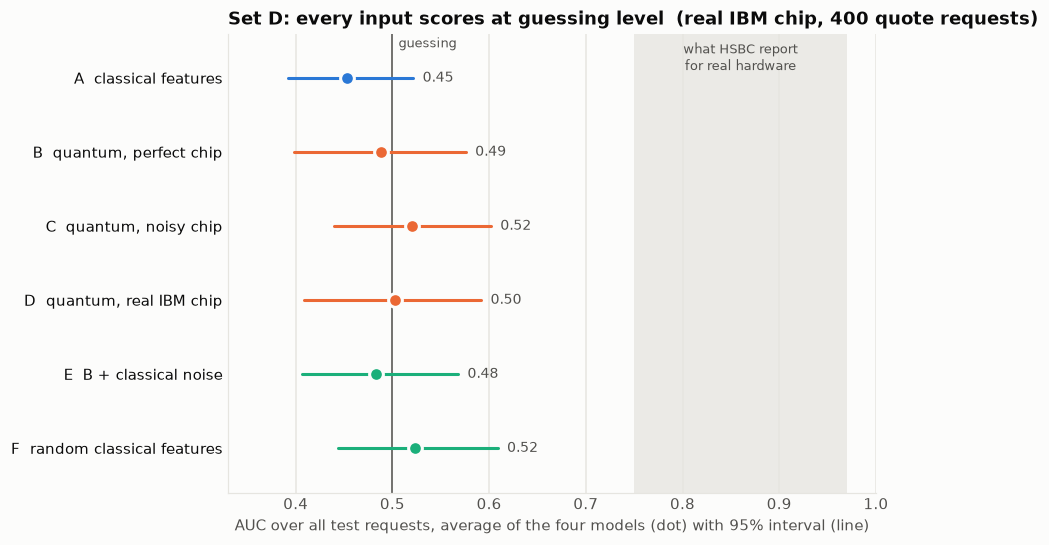

In [4]:
fig = fig_hardware(tab)

**How to read it**

* **Row D is the real chip: 0.50.** Its 95% range runs from 0.41 to 0.59, so it is indistinguishable from guessing.
* **Every row is at guessing level,** including the classical inputs (A). The grey band on the right is where HSBC's reported hardware scores lie. Nothing here comes near it.
* **Do not read anything into the order of the rows.** The ranges all overlap. With about 200 requests to learn from and 196 to test on, differences of a few hundredths are noise. The next section tests the differences properly.
* **The individual models scatter** between 0.42 and 0.55. That scatter is what guessing looks like on 196 requests.

## 4. Is the hardware different from the others?

Two rows of a table can look different by luck. The right test is the **paired difference**: take the same test requests, compare D with another set on exactly those requests, and repeat on re-drawn samples of test days to get a 95% range for the difference. A difference is only real if that range excludes zero.

In [5]:
diff = pd.read_csv(C.TABLES / "partD_hardware_differences.csv")
diff.round(3)

,comparison,difference,ci_low,ci_high,significant
0,D minus A,0.0500,-0.0420,0.1300,False
1,D minus B,0.0150,-0.0230,0.0540,False
2,D minus C,-0.0170,-0.0600,0.0240,False
3,D minus E,0.0200,-0.0750,0.1080,False
4,D minus F,-0.0200,-0.1160,0.0740,False


**No difference is real.** Every range includes zero.

Before the run we wrote down how the result would be read ([PREREGISTRATION.md](../PREREGISTRATION.md), section 7). This is that table, with what happened:

| What we said beforehand | What happened |
|---|---|
| D is no better than A: **no hardware advantage on this data** | **This is what happened.** D minus A is +0.05, with a range of −0.04 to +0.13 |
| D beats A, and the classical imitation E matches D: it was the noise | Does not apply, because D does not beat A |
| D beats A, and D beats E: something unexplained | Does not apply |
| The noise reveals the run position: **the chip drifted** | **This also happened.** See the next section |

Two more comparisons are worth a look:

* **D minus C (−0.02).** The real chip and our noisy *simulation* of a chip behave the same. The simple noise model of Notebook 2 was good enough.
* **D minus E (+0.02).** The real chip and a classical imitation of its noise (the perfect values, shrunk and jittered with ordinary random numbers) behave the same. As far as prediction goes, we found nothing in the hardware's noise that random numbers do not reproduce.

## 5. The clock on a real chip

Notebook 2 raised a worry: a real chip drifts, so its noise changes slowly over time. If requests are sent to the chip in date order, the noise becomes a hidden clock that tells the models roughly *when* each request happened. We guarded against that by shuffling the order. Here is what the real chip did.

In [6]:
d, n = summ["drift"], summ["noise"]
print("How the real chip distorts the perfect values")
print(f"   agreement with the exact simulation (correlation)    {n['correlation_with_perfect_chip']:.3f}")
print(f"   typical shrink factor                                {n['median_shrink']:.3f}")
print(f"   typical random jitter                                {n['median_jitter']:.4f}   (shot noise alone: {n['shot_noise_alone']:.4f})")
print("\nThe check circuit, repeated 21 times through the run")
print(f"   scatter observed / scatter from shot noise alone     {d['excess_ratio']:.2f}     (1 = no drift)")
print("\nCan the chip's noise tell WHEN IN THE RUN a circuit was executed?")
print(f"   first half of the run versus second half             AUC {d['noise_reveals_run_position_auc']:.3f}")
print(f"   97.5% of repeats with shuffled labels stay below     AUC {d['run_position_auc_if_shuffled_975']:.3f}   (chance of 0.773 by luck: {d['run_position_p_value']:.4f})")
print("\nWas the run order related to the DATE of the quote request?")
print(f"   correlation                                          {d['correlation_run_order_vs_date']:+.3f}    (0 = unrelated, as intended)")
print("\nA warning check, explained below (it is NOT a clock)")
print(f"   leftover of the hardware values 'reveals' the date   AUC {d['leftover_reveals_date_auc']:.3f}")
print(f"   the perfect simulated values reveal the date         AUC {d['perfect_chip_values_reveal_date_auc']:.3f}")

How the real chip distorts the perfect values
   agreement with the exact simulation (correlation)    0.993
   typical shrink factor                                0.866
   typical random jitter                                0.0337   (shot noise alone: 0.0303)

The check circuit, repeated 21 times through the run
   scatter observed / scatter from shot noise alone     1.08     (1 = no drift)

Can the chip's noise tell WHEN IN THE RUN a circuit was executed?
   first half of the run versus second half             AUC 0.773
   97.5% of repeats with shuffled labels stay below     AUC 0.574   (chance of 0.773 by luck: 0.0033)

Was the run order related to the DATE of the quote request?
   correlation                                          +0.007    (0 = unrelated, as intended)

A warning check, explained below (it is NOT a clock)
   leftover of the hardware values 'reveals' the date   AUC 0.784
   the perfect simulated values reveal the date         AUC 0.984


**How to read it**

* **The chip works.** Its measurements agree with the exact simulation (correlation 0.99), shrunk by about 13%. Noise can only shrink these values, so that is what a healthy run looks like. It also confirms on real hardware that every measurement is assigned to the right qubit.
* **The noise is mostly ordinary.** The random jitter is barely more than the unavoidable randomness of 1,024 shots.
* **The check circuit barely moved.** Identical circuits scattered 8% more than shot noise alone would explain. Judged by this one circuit, drift was small.
* **Yet the noise carries a time stamp.** A model that sees only the chip's noise can tell first-half circuits from second-half circuits with an AUC of 0.77. In 300 repeats with shuffled labels the test never reached that, and nearly all repeats stayed below 0.58. So over just eight minutes the chip (or the calibration IBM repeats for every job) changed enough to be detected when all 327 measurements are combined.
* **It could not help or mislead us.** Run order and request date are unrelated (correlation 0.007), exactly because the order was shuffled.

**Why this matters.** Anyone who sends requests to a chip *in date order* gives their models the date through the noise. Whether that improves predictions depends on the data: in our simulation (Notebook 3) it did not, because our inputs already contain the date. HSBC's paper notes that the order of processing could leave time-dependent traces, but does not say which order was used.

**A trap worth knowing.** It is tempting to test the clock by asking "does the chip's noise reveal the *date* of a request?". On our data the answer is yes (0.78) even though the run order was random. The reason is that a chip does not distort every input in the same way, so what is left after removing the "perfect" part still depends on the inputs, and our inputs contain the date (market conditions change from day to day). The perfect simulation, with no hardware at all, reveals the date even better (0.98), and the simulated rehearsal in section 10 shows the same effect. So that test says nothing about a clock. The run-position test does, because run position was shuffled and has nothing to do with the inputs.

## 6. What this run can and cannot show

**What it shows**

* On our data, with HSBC's circuit design, on a real IBM chip, with a random run order: **no hardware advantage**, and nothing near the size HSBC report.
* A real chip's noise is, for prediction, **indistinguishable from classical random noise** added to the perfect values.
* A real chip's noise **does encode when a circuit was run**, which is the ingredient the "clock" explanation needs.

**What it cannot show**

* **Small effects.** With 400 requests the 95% range of an AUC is about ±0.09. The run could only have detected a jump far outside that, which is what HSBC claim (from about 0.63 to between 0.75 and 0.97). Differences like the 0.02 of Notebook 3 would need thousands of requests. (With both sessions combined, section 10b, the range narrows to about ±0.05.)
* **Anything about a signal that is not there.** Even the classical inputs score at guessing level here, because about 200 requests are too few to learn the weak signal of Notebook 1. So the question this run answers is "does hardware make a signal appear out of nowhere?", and the answer is no.
* **That HSBC's result is wrong.** Our fills come from a simulated dealer on public data, not from real quote requests. We used one chip on one day, the shorter of HSBC's two circuits, 98 inputs instead of 216, and 1,024 shots instead of 4,096.
* **That date order would have produced a gain.** We did not send a date-ordered batch to the chip. We showed that the time stamp exists, not what it does to predictions on hardware.

## 7. How the run was done, so that you can repeat it

**What you need**

* An IBM Quantum account. The free **Open Plan** gives 10 minutes (600 "quantum seconds") of quantum time per rolling 28 days. IBM's plans page also describes an opt-in for extra free time for active Open Plan users (since March 2026); look for it on your account page.
* Your API key saved once on this computer. Do this yourself in a Python prompt; never paste the key into a script, a notebook or a chat:

```python
from qiskit_ibm_runtime import QiskitRuntimeService
QiskitRuntimeService.save_account(token="<your key>", instance="<your instance CRN>")
```

**Step 1 — dry run on a simulated chip (free, no account, about 2 minutes)**

```bash
.venv/bin/python scripts/06_hardware_run.py --mode local
```

Checks that the 109-qubit circuit fits on the chip, then runs a 12-qubit version of exactly the same pipeline on a simulated copy of ibm_fez and compares the answers with the exact simulation. (Simulating a *noisy* 109-qubit chip gate by gate would take hours, which is why the rehearsal circuit is short.)

**Step 2 — timing job on the real chip**

```bash
.venv/bin/python scripts/06_hardware_run.py --mode timing --backend ibm_fez
```

Runs 5 circuits and prints what IBM charged for them. In our run this cost 9 quantum seconds.

**Step 3 — the real run**

```bash
.venv/bin/python scripts/06_hardware_run.py --mode run --backend ibm_fez --events 400 --shots 1024 --budget-seconds 480
```

In our run this cost 397 quantum seconds: 47 for each job of 50 circuits. It took eight minutes from the first job to the last.

**Step 4 — analyse it**

```bash
.venv/bin/python scripts/07_analyse_hardware.py
```

**How the script protects your 10 minutes**

| Protection | What it does |
|---|---|
| **Estimate** | By IBM's published formula these settings need about 6 to 8 minutes of quantum time. The real run used 6.6. HSBC's 4,096 shots would need about 22 minutes, which is why we used 1,024. |
| **Budget** | `--budget-seconds` (default 480, which is 8 minutes) is the most the script spends in one session. After every job it reads what IBM really charged, and it does not send the next job if that would cross the budget. IBM is also told to cancel any single job that overruns what is left. |
| **Nothing is lost** | Results are saved after every job of 50 circuits. If the run stops for any reason (budget, a failed job, a closed laptop), give the same command again: it continues where it stopped and repeats nothing. |
| **A shortened run is still valid** | Events go in random order, so whatever was measured before a stop is a fair random sample of the plan. |
| **It will not overwrite results** | If saved results exist with different settings, the script refuses to run. `--fresh` starts again and keeps the old files under a new name. |

In the real run IBM reported the remaining allowance, accepted the per-job limit and reported the charge for every job, so all three protections that depend on IBM's servers worked. The stop itself was never needed, because the run finished inside the budget; that part is tested only with pretend prices on a simulated chip (`tests/test_hardware.py`). If you continue a stopped run on a later day, say so when reporting: the chip may have been recalibrated in between.

Here is the output of the dry run (step 1) on this machine:

In [7]:
log = (C.ROOT / "results" / "logs" / "hardware_dry_run.log").read_text().splitlines()
print("\n".join(line for line in log if "arn" not in line))

DRY RUN on a simulated copy of ibm_fez (no account, no quantum time).
  full circuit fits: 109 qubits in a row, depth 80, 648 entangling gates
  the real run (400 events = 421 circuits, 1024 shots) is estimated at 6.1 to 8.1 minutes of quantum time;
  the free plan gives 10 minutes per 28 days, and the script stops by itself at 8.
  executing the 12-qubit version on the simulated chip ...
backend: fake_fez   12-qubit chain starts [140, 141, 142, 143, 144, 145, 146, 147] ...
  median two-qubit gate error on the chain: 0.0031   worst: 0.0040
  transpiled circuit: depth 80, gates {'rz': 376, 'sx': 200, 'cz': 66, 'barrier': 4}
  plan: 12 events + 2 sentinel repeats = 14 circuits, 256 shots x 3 measurement bases each
  job 1: 14 circuits sent (id 728de48b-2c60-4963-9f4a-ff19cdcf9476)
         done (14 of 14 circuits)
run complete: 14 circuits saved in hardware_features_LOCAL_DRY_RUN.parquet
sentinel check (identical circuits repeated through the run):
  n_sentinels: 2
  median_observed_std:

**How to read it.** The last line is the important one: the values measured on the simulated chip agree with the exact simulation (correlation about 0.99), shrunk by a few percent. That is exactly what noise should do, and it confirms that the pipeline assigns each measurement to the right qubit. The real chip gave the same picture (section 5).

## 8. What the circuit looks like on a real chip

IBM chips are not a straight line of qubits; they are a honeycomb ("heavy-hex"). Our circuit needs 109 qubits in a row, so `find_chain` looks for a snake-like path through the honeycomb, avoiding the worst couplers. The circuit is then translated ("transpiled") into the chip's own gates. The cell below does this on Qiskit's stored copy of ibm_fez and then shows the path that was used on the live chip.

In [8]:
from qiskit_ibm_runtime.fake_provider import FakeFez
from qon.circuit import make_spec
from qon.hardware import find_chain, prepare, chip_snapshot
fake = FakeFez()
spec = make_spec(n_features=98)
chain = find_chain(fake, spec.n_qubits)
prepared = prepare(spec, fake, chain)
snap = chip_snapshot(fake, chain)
ops = prepared.isa_circuit.count_ops()
print(f"chip: {fake.name} ({fake.num_qubits} qubits);  path of {len(chain)} connected qubits found")
print(f"path starts: {chain[:12]} ...")
print(f"two-qubit gates on the chip: {ops.get('cz', 0)}  (= 216 Heisenberg gates x 3)")
print(f"circuit depth after translation: {prepared.isa_circuit.depth()} gate layers")
print(f"typical two-qubit gate error on the path: {np.median(snap['two_qubit_error']):.2%}; worst: {max(snap['two_qubit_error']):.2%}")
print(f"\npath used on the live chip on the day of the run: {run['chain'][:12]} ...  ({len(run['chain'])} qubits)")
print("(the live chip's error rates differ from the stored copy, so the best path differs too)")

chip: fake_fez (156 qubits);  path of 109 connected qubits found
path starts: [139, 135, 134, 133, 132, 131, 130, 129, 118, 109, 110, 111] ...
two-qubit gates on the chip: 648  (= 216 Heisenberg gates x 3)
circuit depth after translation: 80 gate layers
typical two-qubit gate error on the path: 0.39%; worst: 1.57%

path used on the live chip on the day of the run: [68, 67, 66, 65, 77, 85, 84, 83, 82, 81, 76, 61] ...  (109 qubits)
(the live chip's error rates differ from the stored copy, so the best path differs too)


A detail that matters for noise: written naively, each Heisenberg gate would need **six** entangling gates on the chip. We use a standard construction that needs **three** (`heisenberg_gate` in `circuit.py`; a test proves both are the same operation). Entangling gates are the noisiest thing a chip does, so this halves the damage.

## 9. The controls that were built in

These are the controls HSBC's critics asked for. They were fixed in [PREREGISTRATION.md](../PREREGISTRATION.md) before any quantum time was spent.

| Control | What it does | Why |
|---|---|---|
| **Random run order** | events are sent in a shuffled order, not by date | so that slow drift of the chip cannot act as a hidden clock (Notebook 2, section 9) |
| **Sentinel circuits** | one fixed circuit is repeated after every 20 events | identical inputs should give identical outputs; any extra scatter is drift, measured directly |
| **Same error handling as HSBC** | Pauli twirling + TREX, nothing else | so that the comparison is like for like |
| **Classical noise twin (set E)** | the perfect values, shrunk and jittered to match the hardware | to test whether hardware noise is anything more than classical noise |
| **Everything written down first** | one circuit, one seed, one protocol | so that nobody can pick the best of several attempts afterwards |

Three checks were added **after** the run, to state the result precisely: the paired differences of section 4, the shuffled-label test of section 5, and the warning check about dates. They are recorded as additions in PREREGISTRATION.md, section 10, and they do not change the planned reading of the result.

## 10. The rehearsal that came first

To make sure the analysis worked before spending quantum time, `scripts/07_analyse_hardware.py --rehearsal` builds a **stand-in** results file from the noisy simulator (600 events, random order, with sentinels) and runs the complete analysis on it.

**These are simulated numbers. They say nothing about real hardware.** They are kept because they show the analysis was written and tested before the real result existed.

In [9]:
rtab = pd.read_csv(C.TABLES / "partD_REHEARSAL_auc.csv")
rsumm = json.loads((C.TABLES / "partD_REHEARSAL_summary.json").read_text())
print(f"REHEARSAL (simulated): {rsumm['n_events']} events, {rsumm['n_test_events']} of them used for testing\n")
rwide = rtab.pivot(index="set", columns="model", values="auc")[["All", "LR", "RF", "XGB", "NN"]]
low = rtab[rtab.model == "All"].set_index("set")["ci_low"]; high = rtab[rtab.model == "All"].set_index("set")["ci_high"]
rwide["All: 95% low"], rwide["All: 95% high"] = low, high
rwide.round(3)

REHEARSAL (simulated): 600 events, 294 of them used for testing



model,All,LR,RF,XGB,NN,All: 95% low,All: 95% high
set,,,,,,,
A,0.4950,0.4810,0.4970,0.4910,0.5160,0.4220,0.5700
B,0.4930,0.5060,0.5030,0.4930,0.4790,0.4270,0.5640
C,0.5100,0.5130,0.5360,0.5380,0.4630,0.4460,0.5700
D,0.4780,0.4960,0.5190,0.4560,0.4680,0.4120,0.5480
E,0.4930,0.5100,0.4980,0.4890,0.4710,0.4280,0.5620
F,0.4850,0.5090,0.4450,0.5040,0.4470,0.4340,0.5430


In [10]:
print("How the (simulated) chip distorts the perfect values:")
for k, v in rsumm["noise"].items(): print(f"   {k:38s} {v:.4f}")
print("\nDrift checks:")
for k, v in rsumm["drift"].items(): print(f"   {k:38s} {v:.4f}" if isinstance(v, float) else f"   {k:38s} {v}")

How the (simulated) chip distorts the perfect values:
   median_shrink                          0.8990
   median_jitter                          0.0166
   shot_noise_alone                       0.0151
   correlation_with_perfect_chip          0.9984

Drift checks:
   n_sentinels                            31
   median_observed_std                    0.0139
   median_shot_noise_std                  0.0146
   excess_ratio                           0.9526
   median_shift_first_vs_second_half      0.0035
   correlation_run_order_vs_date          0.0264
   noise_reveals_run_position_auc         0.4733
   run_position_auc_if_shuffled_975       0.5679
   run_position_p_value                   0.7342
   leftover_reveals_date_auc              0.8954
   perfect_chip_values_reveal_date_auc    0.9873


**The rehearsal predicted the shape of the real result.** With a few hundred events every set scores at guessing level, classical inputs included, so only a large jump could show.

**One difference is instructive.** In the rehearsal the noise does *not* reveal the run position (0.47). On the real chip it does (0.77). Our simulated drift was too gentle over a few hundred circuits; the real chip changes faster than we assumed.

## 10b. A second session, and both sessions combined (added 15 November 2026)

A teammate repeated the run from their own free account on the same day, 23:43 to 23:58 UTC, about six hours after the first session. It used the same chip, the same 109 qubits, the same settings and the same dataset, and asked for 600 requests in a new random order. It stopped by itself at the spending limit after 523 requests. Thirteen of them had also been measured in the first session, so the two sessions together cover 910 different requests.

`scripts/08_combine_runs.py` puts the two sessions together (for the 13 repeated requests it keeps the first session's values) and runs exactly the analysis of sections 3 to 5 on all 910.

**This was not in the plan.** Combining the sessions was decided after both had run. Read it as a larger repeat of the same test, not as a pre-registered result.

In [ ]:
ctab = pd.read_csv(C.TABLES / "partD_combined_auc.csv")
csumm = json.loads((C.TABLES / "partD_combined_summary.json").read_text())
run2 = json.loads((RUN / "run2_hardware_features.json").read_text())
print(f"second session: {run2['n_circuits_done']} circuits, {run2['quantum_seconds_used']:.0f} quantum seconds, "
      f"stopped by the spending limit of {run2['budget_seconds']:.0f}")
print(f"both sessions: {csumm['n_events']} quote requests; {csumm['n_test_events']} of them used for testing\n")
print(ctab[ctab.model == "All"][["set", "auc", "ci_low", "ci_high"]].round(3).to_string(index=False))
print("\nIs D different from the others?")
print(pd.read_csv(C.TABLES / "partD_combined_differences.csv").round(3).to_string(index=False))
print("\nThe two sessions compared")
for k, v in csumm["two_runs"].items(): print(f"   {k:40s} {v:.4f}" if isinstance(v, float) else f"   {k:40s} {v}")

second session: 550 circuits, 517 quantum seconds, stopped by the spending limit of 570
both sessions: 910 quote requests; 449 of them used for testing

set   auc  ci_low  ci_high
  A 0.525   0.495    0.555
  B 0.525   0.470    0.580
  C 0.513   0.465    0.564
  D 0.535   0.481    0.588
  E 0.535   0.481    0.582
  F 0.512   0.464    0.559

Is D different from the others?
comparison  difference  ci_low  ci_high  significant
 D minus A       0.010  -0.043    0.064        False
 D minus B       0.010  -0.022    0.042        False
 D minus C       0.022  -0.011    0.052        False
 D minus E       0.000  -0.036    0.038        False
 D minus F       0.023  -0.047    0.096        False

The two sessions compared
   events_in_both_runs                      13
   agreement_between_runs_correlation       0.9902
   median_abs_difference_between_runs       0.0335
   noise_reveals_which_run_auc              0.9992
   which_run_auc_if_shuffled_975            0.5473
   which_run_p_value         

**How to read it**

* **Still no advantage.** The real chip scores 0.54 (0.48 to 0.59) and the classical inputs 0.52. The difference is +0.01, with a range of −0.04 to +0.06, so a gain larger than about 0.06 is ruled out on our data.
* **The chip's noise is ordinary.** D minus E, the classical imitation of its noise, is 0.00 (−0.04 to +0.04).
* **The classical baseline looks normal again.** The 0.45 of the first session was the luck of a small sample.
* **The two sessions agree** on the 13 requests they share (correlation 0.99).
* **The clock is unmistakable.** From the noise alone, a model tells which session a circuit ran in with AUC 0.999. Over six hours the chip's errors changed enough to stamp every result with when it ran. Both sessions were in random order, so the stamp is unrelated to the requests' dates (correlation 0.00) and could not help the predictions. Sent in date order, it would have.
* **The second session alone** gave D minus A = −0.03 (−0.13 to +0.07), and a within-session run-position AUC of 0.70.
* **One thing is not pooled.** Each session repeated its own check circuit, so the check-circuit numbers of section 5 cannot be combined across sessions. Each session's own figure is 1.08.


## 11. Every limitation of this project in one place

**Data**

1. The fill label is a stand-in: a simple simulated dealer replayed against real trade prices. Real quote requests are private.
2. Only requests that ended in a trade are visible; requests where the customer walked away are not.
3. Daily data, not time-stamped to the microsecond like HSBC's.
4. US corporate bonds, not European.
5. 97 of the 216 listed features (all that are free) plus the side of the request. No ratings, company accounts, share prices, CDS or holdings.
6. Only liquid, seasoned bonds.
7. The signal is weak (classical AUC about 0.55, against about 0.63 for HSBC), so small differences between methods are hard to see.

**Quantum**

8. **Two small hardware runs.** 910 quote requests in all, one chip (ibm_fez), one day, 1,024 shots per measurement where HSBC used 4,096. They can only detect a difference in AUC larger than about 0.06. Combining them was decided after both had run.
9. The hardware run used a random order only. We did not also send a date-ordered batch, so the clock is shown to exist on hardware but its effect on predictions is shown only in simulation.
10. The simulated noise is a simplified model: random gate errors, readout errors, shot noise and slow drift. Real chips also have crosstalk, leakage and other effects, and the real chip drifted faster than our model.
11. With 98 inputs instead of 216, each input drives two or three gates. HSBC's "longer" circuit (twice the depth, the one behind their 34%) was neither simulated nor run.
12. One circuit, one seed. That is deliberate (no cherry-picking), but other seeds were not explored.

**Statistics**

13. One 68-day window. Markets in other periods may behave differently.
14. Many comparisons are reported; a few "real" differences will appear by chance. We rely on the consistent overall picture, not on any single cell.
15. Our hyper-parameter grids are smaller than HSBC's.
16. Three checks on the hardware result were added after seeing it (section 9). They are labelled as such.

## 12. Ideas for going further

* **Send one batch in date order** as well as a random-order batch. We now know the chip's noise carries a time stamp; this would show directly whether that leaks dates into predictions on real hardware.
* **Repeat the run on a second day or chip**, to see whether the picture holds.
* **Run thousands of requests** (IBM's opt-in allowance of 180 minutes would do it), so that small effects become visible.
* **Run HSBC's longer circuit**, the one their 34% comes from.
* **Try other seeds** for the start state and the feature-to-gate map, and report all of them.
* **A richer fill label**, if anyone can get access to real quote data.

**Back to the start:** [Notebook 0](00_START_HERE.ipynb).